# Assemble and Visualize Full Point Cloud from Chunks

This notebook reconstructs the full point cloud from spatial grid chunks and visualizes:
- Complete test set point cloud
- Ground truth labels
- Model predictions
- Side-by-side comparison

The chunks were created using spatial grid tiling, so we can reconstruct the original spatial layout.

## 1. Configuration

In [12]:
# Configuration
DATA_DIR = '../data/processed_data_optimized'

# Use the latest checkpoint (Oct 16) - compatible with fixed architecture
CHECKPOINT_PATH = 'checkpoints/model_2_num_epochs_3_val_miou=0.575.ckpt'

# NOTE: The older checkpoint (pointtransformer-epoch=00-val_miou=0.487.ckpt from Oct 10)
# uses the OLD architecture before bug fixes and is INCOMPATIBLE with this notebook.
# You must use checkpoints from Oct 16 onwards that were trained with the fixed architecture.

OUTPUT_DIR = 'full_reconstructions'

# Visualization settings
MAX_CHUNKS_TO_LOAD = None  # None = all chunks, or specify number (e.g., 100)
DOWNSAMPLE_FACTOR = 1  # Downsample for faster visualization (1 = no downsample, 2 = half, etc.)
FIGURE_SIZE = (20, 10)
POINT_SIZE = 1
DPI = 150

# Class information
CLASS_NAMES = ['High Vegetation', 'Power Lines', 'Pylons', 'Others']
CLASS_COLORS = ['darkgreen', 'orange', 'blue', 'gray']

print("Configuration loaded!")
print(f"Data directory: {DATA_DIR}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Output directory: {OUTPUT_DIR}")
print("\nNote: Using checkpoint from Oct 16 with fixed architecture (val_miou=0.421)")
print("The older Oct 10 checkpoint (val_miou=0.487) is incompatible and cannot be loaded.")

Configuration loaded!
Data directory: ../data/processed_data_optimized
Checkpoint: checkpoints/model_2_num_epochs_3_val_miou=0.575.ckpt
Output directory: full_reconstructions

Note: Using checkpoint from Oct 16 with fixed architecture (val_miou=0.421)
The older Oct 10 checkpoint (val_miou=0.487) is incompatible and cannot be loaded.


## 2. Imports

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from pathlib import Path
import json
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"MPS available: {torch.backends.mps.is_available()}")

PyTorch version: 2.7.1
CUDA available: False
MPS available: True


## 3. Model Architecture (same as training)

In [14]:
def knn(x, k):
    """Find k nearest neighbors"""
    inner = -2 * torch.matmul(x.transpose(2, 1), x)
    xx = torch.sum(x**2, dim=1, keepdim=True)
    pairwise_distance = -xx - inner - xx.transpose(2, 1)
    idx = pairwise_distance.topk(k=k, dim=-1)[1]
    return idx


class TransformerBlock(nn.Module):
    """Point Transformer Block"""
    def __init__(self, d_model, num_heads=8, k=16):
        super().__init__()
        self.d_model = d_model
        self.k = k
        self.q = nn.Linear(d_model, d_model)
        self.k_linear = nn.Linear(d_model, d_model)
        self.v = nn.Linear(d_model, d_model)
        self.pos_mlp = nn.Sequential(nn.Linear(3, d_model), nn.ReLU(), nn.Linear(d_model, d_model))
        self.ffn = nn.Sequential(nn.Linear(d_model, d_model * 4), nn.ReLU(), nn.Linear(d_model * 4, d_model))
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, features, positions, k=None):
        if k is None:
            k = self.k
        
        B, N, C = features.shape
        idx = knn(positions.transpose(1, 2), k)
        
        idx_base = torch.arange(0, B, device=features.device).view(-1, 1, 1) * N
        idx_expanded = (idx + idx_base).view(B * N * k)
        
        features_flat = features.view(B * N, C)
        neighbor_features = features_flat[idx_expanded].view(B, N, k, C)
        
        positions_flat = positions.view(B * N, 3)
        neighbor_positions = positions_flat[idx_expanded].view(B, N, k, 3)
        
        relative_pos = positions.unsqueeze(2) - neighbor_positions
        pos_encoding = self.pos_mlp(relative_pos)
        
        q = self.q(features).unsqueeze(2)
        k_feat = self.k_linear(neighbor_features) + pos_encoding
        v = self.v(neighbor_features) + pos_encoding
        
        attn = torch.matmul(q, k_feat.transpose(-2, -1)) / (C ** 0.5)
        attn = F.softmax(attn, dim=-1)
        out = torch.matmul(attn, v).squeeze(2)
        
        features = self.norm1(features + out)
        out = self.ffn(features)
        features = self.norm2(features + out)
        return features


class PointTransformerV2(nn.Module):
    """Point Transformer V2 for semantic segmentation"""
    def __init__(self, num_classes=4, d_model=128, num_layers=2, k=16, dropout=0.3):
        super().__init__()
        self.num_classes = num_classes
        self.input_embed = nn.Sequential(nn.Linear(3, 64), nn.ReLU(), nn.Linear(64, d_model))
        self.blocks = nn.ModuleList([TransformerBlock(d_model, k=k) for _ in range(num_layers)])
        self.seg_head = nn.Sequential(
            nn.Linear(d_model, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, points):
        features = self.input_embed(points)
        for block in self.blocks:
            features = block(features, points)
        logits = self.seg_head(features)
        return logits


print("Model classes defined!")

Model classes defined!


## 4. Load Model

In [15]:
# Device setup
if torch.cuda.is_available():
    device = 'cuda'
    print("Using CUDA GPU")
elif torch.backends.mps.is_available():
    device = 'mps'
    print("Using Apple Silicon MPS")
else:
    device = 'cpu'
    print("Using CPU")

# Load checkpoint
checkpoint_path = Path(CHECKPOINT_PATH)
if not checkpoint_path.exists():
    raise FileNotFoundError(f"Checkpoint not found at {checkpoint_path}")

print(f"\nLoading model from {checkpoint_path}...")
checkpoint = torch.load(checkpoint_path, map_location=device)

# Extract hyperparameters
hparams = checkpoint['hyper_parameters']
print(f"Model hyperparameters:")
print(f"  num_classes: {hparams['num_classes']}")
print(f"  d_model: {hparams['d_model']}")
print(f"  num_layers: {hparams['num_layers']}")
print(f"  k: {hparams.get('k', 16)}")

# Create model
model = PointTransformerV2(
    num_classes=hparams['num_classes'],
    d_model=hparams['d_model'],
    num_layers=hparams['num_layers'],
    k=hparams.get('k', 16),
    dropout=0.3
)

# Load state dict
state_dict = {k.replace('model.', ''): v for k, v in checkpoint['state_dict'].items() if k.startswith('model.')}
model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print(f"\nModel loaded successfully!")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Using Apple Silicon MPS

Loading model from checkpoints/model_2_num_epochs_3_val_miou=0.575.ckpt...
Model hyperparameters:
  num_classes: 4
  d_model: 156
  num_layers: 3
  k: 16

Model loaded successfully!
Total parameters: 968,052


## 5. Load and Reconstruct Full Point Cloud

In [16]:
# Load test chunks
test_dir = Path(DATA_DIR) / 'test'
chunk_files = sorted(list(test_dir.glob('*.pt')))

if MAX_CHUNKS_TO_LOAD is not None:
    chunk_files = chunk_files[:MAX_CHUNKS_TO_LOAD]

print(f"Found {len(chunk_files)} test chunks")

# Initialize lists to store all points
all_points = []
all_labels = []
all_predictions = []

print(f"\nLoading and predicting chunks...")
with torch.no_grad():
    for chunk_file in tqdm(chunk_files, desc="Processing chunks"):
        # Load chunk
        chunk_data = torch.load(chunk_file, weights_only=False)
        points = chunk_data['input_pcd']
        labels = chunk_data['semantic_labels']
        
        # Ensure labels is 1D
        labels = labels.reshape(-1)
        
        # Convert to 0-indexed
        labels = labels - 1
        
        # Get metadata (contains centroid for denormalization)
        metadata = chunk_data.get('metadata', {})
        centroid = metadata.get('centroid', None)
        
        # Denormalize points (add centroid back)
        if centroid is not None:
            if isinstance(centroid, list):
                centroid = np.array(centroid)
            elif isinstance(centroid, torch.Tensor):
                centroid = centroid.numpy()
            points_denorm = points.numpy() + centroid
        else:
            points_denorm = points.numpy()
        
        # Predict (need to handle point count)
        n_points = points.shape[0]
        
        # If too many points, sample
        if n_points > 4096:
            indices = np.random.choice(n_points, 4096, replace=False)
            points_pred = points[indices].unsqueeze(0).to(device)
            logits = model(points_pred)
            pred = logits.argmax(dim=-1).cpu().numpy()[0]
            
            # Create full prediction array
            full_pred = np.zeros(n_points, dtype=np.int64)
            full_pred[indices] = pred
            # For unsampled points, use nearest sampled point's prediction
            # (Simple approach: just use most common class for unsampled)
            unsampled_mask = np.ones(n_points, dtype=bool)
            unsampled_mask[indices] = False
            if unsampled_mask.sum() > 0:
                most_common_class = np.bincount(pred).argmax()
                full_pred[unsampled_mask] = most_common_class
            pred = full_pred
        
        # If too few points, pad
        elif n_points < 4096:
            padded_points = torch.zeros(4096, 3)
            padded_points[:n_points] = points
            
            points_pred = padded_points.unsqueeze(0).to(device)
            logits = model(points_pred)
            pred = logits.argmax(dim=-1).cpu().numpy()[0][:n_points]
        
        else:
            points_pred = points.unsqueeze(0).to(device)
            logits = model(points_pred)
            pred = logits.argmax(dim=-1).cpu().numpy()[0]
        
        # Downsample if needed
        if DOWNSAMPLE_FACTOR > 1:
            indices = np.arange(0, n_points, DOWNSAMPLE_FACTOR)
            points_denorm = points_denorm[indices]
            labels = labels[indices]
            pred = pred[indices]
        
        # Append to lists
        all_points.append(points_denorm)
        all_labels.append(labels.numpy())
        all_predictions.append(pred)

# Concatenate all chunks
all_points = np.vstack(all_points)
all_labels = np.concatenate(all_labels)
all_predictions = np.concatenate(all_predictions)

print(f"\nReconstructed point cloud:")
print(f"  Total points: {len(all_points):,}")
print(f"  X range: [{all_points[:, 0].min():.2f}, {all_points[:, 0].max():.2f}]")
print(f"  Y range: [{all_points[:, 1].min():.2f}, {all_points[:, 1].max():.2f}]")
print(f"  Z range: [{all_points[:, 2].min():.2f}, {all_points[:, 2].max():.2f}]")

Found 6203 test chunks

Loading and predicting chunks...


Processing chunks:   7%|▋         | 429/6203 [05:24<1:12:41,  1.32it/s]


KeyboardInterrupt: 

## 6. Compute Overall Metrics

In [ ]:
# Compute per-class metrics
print("\n" + "="*80)
print("FULL POINT CLOUD METRICS")
print("="*80)

metrics = {}
for cls in range(4):
    pred_mask = all_predictions == cls
    true_mask = all_labels == cls
    
    tp = np.sum(pred_mask & true_mask)
    fp = np.sum(pred_mask & ~true_mask)
    fn = np.sum(~pred_mask & true_mask)
    
    iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    metrics[CLASS_NAMES[cls]] = {
        'IoU': iou,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'Count': np.sum(true_mask)
    }
    
    print(f"\n{CLASS_NAMES[cls]}:")
    print(f"  IoU:       {iou:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  Points:    {np.sum(true_mask):,} ({100*np.sum(true_mask)/len(all_labels):.2f}%)")

mean_iou = np.mean([m['IoU'] for m in metrics.values()])
print(f"\n{'='*80}")
print(f"Mean IoU: {mean_iou:.4f}")
print(f"Overall Accuracy: {(all_predictions == all_labels).mean():.4f}")
print(f"{'='*80}")


FULL POINT CLOUD METRICS

High Vegetation:
  IoU:       0.6347
  Precision: 0.7376
  Recall:    0.8199
  F1-Score:  0.7766
  Points:    13,404,162 (59.60%)

Power Lines:
  IoU:       0.6177
  Precision: 0.7576
  Recall:    0.7699
  F1-Score:  0.7637
  Points:    40,615 (0.18%)

Pylons:
  IoU:       0.0000
  Precision: 0.0000
  Recall:    0.0000
  F1-Score:  0.0000
  Points:    2,246 (0.01%)

Others:
  IoU:       0.4484
  Precision: 0.6804
  Recall:    0.5681
  F1-Score:  0.6192
  Points:    9,043,655 (40.21%)

Mean IoU: 0.4252
Overall Accuracy: 0.7184


## 7. Visualize Full Point Cloud - Top View

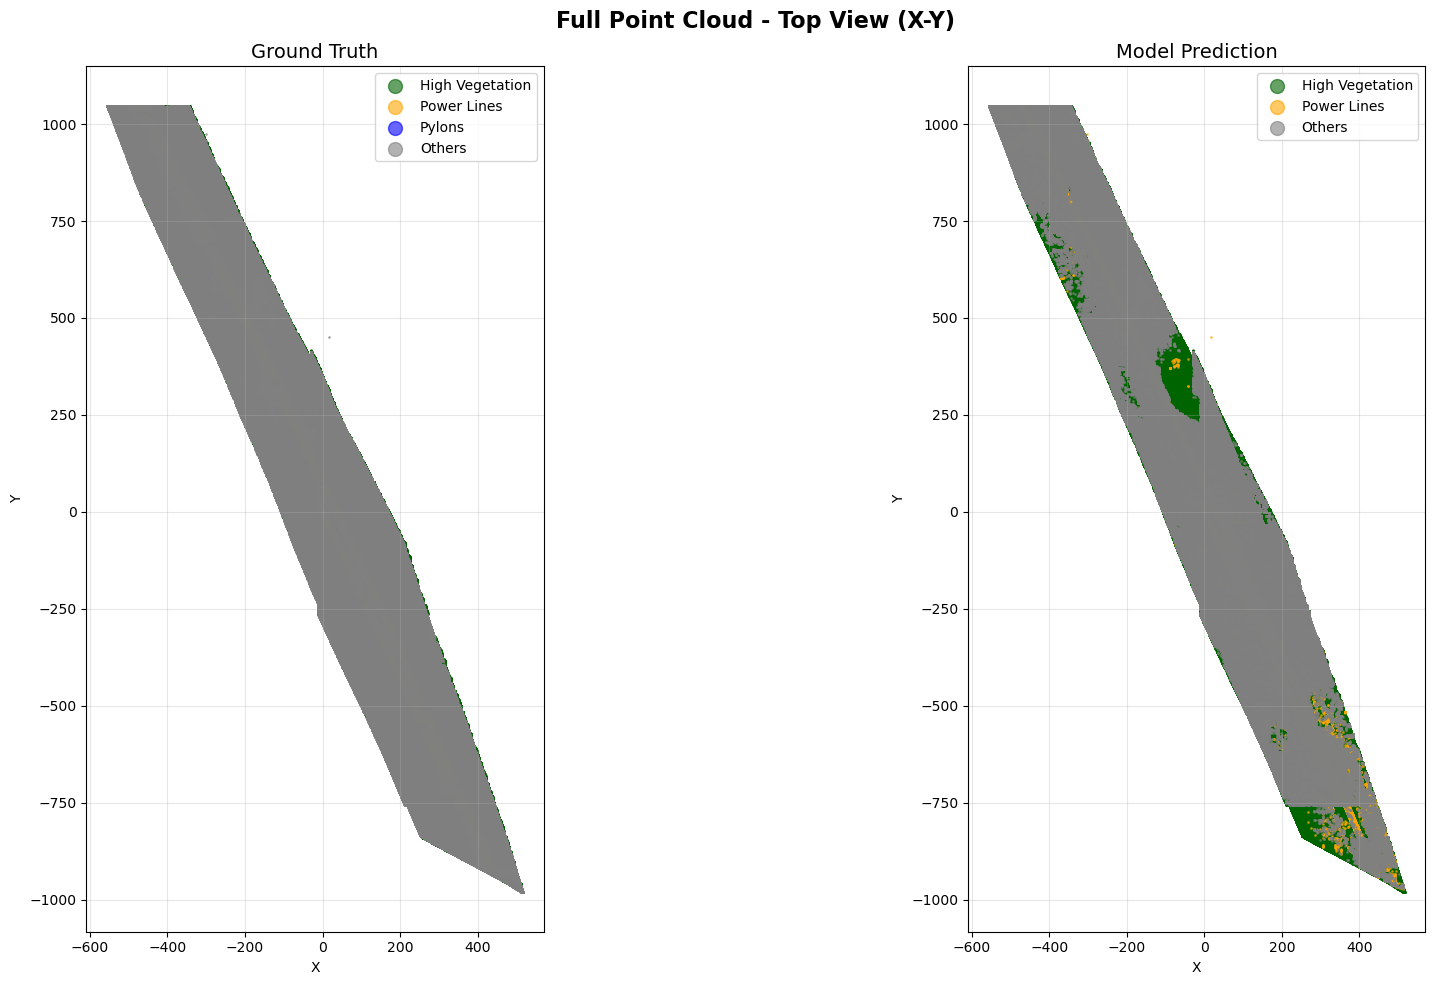

Saved top view to full_reconstructions/full_pointcloud_topview.png


In [ ]:
# Create output directory
Path(OUTPUT_DIR).mkdir(exist_ok=True)

# Top-down view (X-Y plane)
fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE)
fig.suptitle('Full Point Cloud - Top View (X-Y)', fontsize=16, fontweight='bold')

# Ground Truth
ax1 = axes[0]
ax1.set_title('Ground Truth', fontsize=14)
for cls in range(4):
    mask = all_labels == cls
    if mask.sum() > 0:
        ax1.scatter(all_points[mask, 0], all_points[mask, 1], 
                   c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=POINT_SIZE, alpha=0.6)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.legend(loc='upper right', markerscale=10)
ax1.set_aspect('equal')
ax1.grid(True, alpha=0.3)

# Prediction
ax2 = axes[1]
ax2.set_title('Model Prediction', fontsize=14)
for cls in range(4):
    mask = all_predictions == cls
    if mask.sum() > 0:
        ax2.scatter(all_points[mask, 0], all_points[mask, 1], 
                   c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=POINT_SIZE, alpha=0.6)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.legend(loc='upper right', markerscale=10)
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/full_pointcloud_topview.png', dpi=DPI, bbox_inches='tight')
plt.show()

print(f"Saved top view to {OUTPUT_DIR}/full_pointcloud_topview.png")

## 8. Visualize Full Point Cloud - 3D View

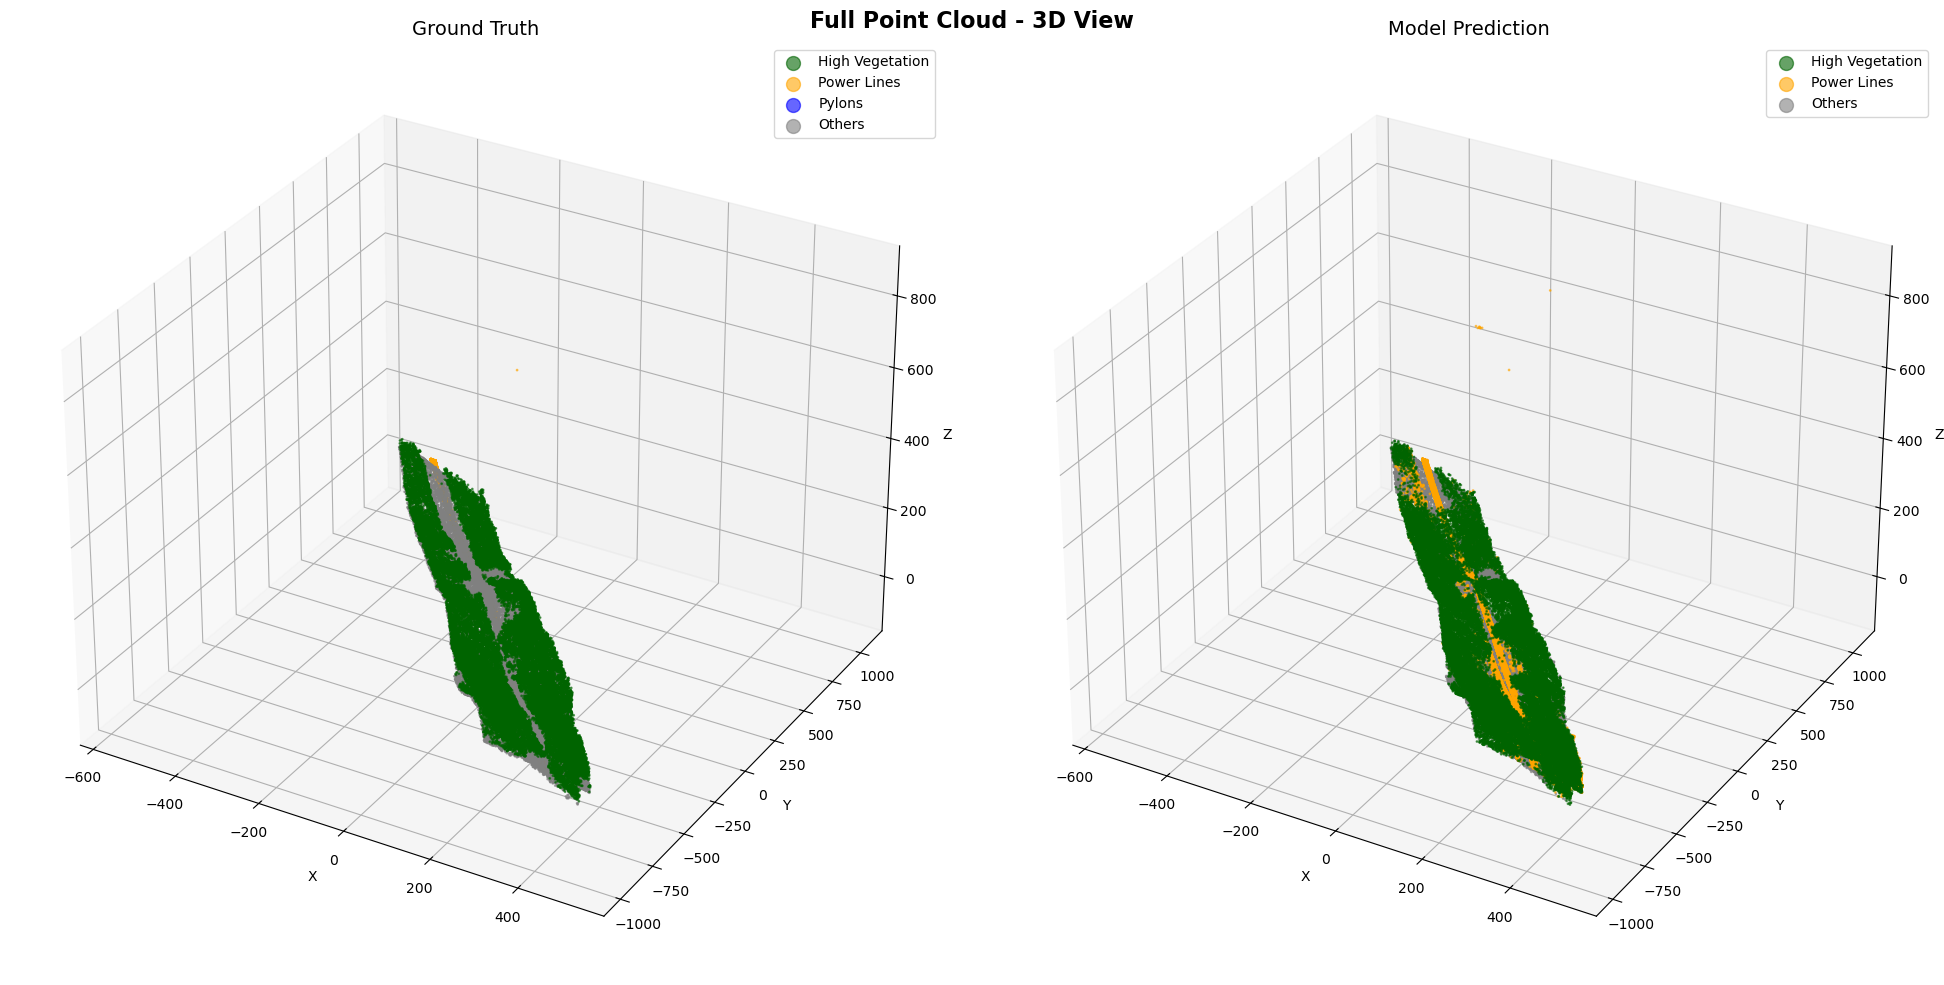

Saved 3D view to full_reconstructions/full_pointcloud_3d.png


In [ ]:
# 3D visualization
fig = plt.figure(figsize=FIGURE_SIZE)
fig.suptitle('Full Point Cloud - 3D View', fontsize=16, fontweight='bold')

# Ground Truth
ax1 = fig.add_subplot(121, projection='3d')
ax1.set_title('Ground Truth', fontsize=14)
for cls in range(4):
    mask = all_labels == cls
    if mask.sum() > 0:
        # Sample for visualization if too many points
        if mask.sum() > 50000:
            indices = np.random.choice(np.where(mask)[0], 50000, replace=False)
            ax1.scatter(all_points[indices, 0], all_points[indices, 1], all_points[indices, 2],
                       c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=POINT_SIZE, alpha=0.6)
        else:
            ax1.scatter(all_points[mask, 0], all_points[mask, 1], all_points[mask, 2],
                       c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=POINT_SIZE, alpha=0.6)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.legend(loc='upper right', markerscale=10)

# Prediction
ax2 = fig.add_subplot(122, projection='3d')
ax2.set_title('Model Prediction', fontsize=14)
for cls in range(4):
    mask = all_predictions == cls
    if mask.sum() > 0:
        # Sample for visualization if too many points
        if mask.sum() > 50000:
            indices = np.random.choice(np.where(mask)[0], 50000, replace=False)
            ax2.scatter(all_points[indices, 0], all_points[indices, 1], all_points[indices, 2],
                       c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=POINT_SIZE, alpha=0.6)
        else:
            ax2.scatter(all_points[mask, 0], all_points[mask, 1], all_points[mask, 2],
                       c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=POINT_SIZE, alpha=0.6)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')
ax2.legend(loc='upper right', markerscale=10)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/full_pointcloud_3d.png', dpi=DPI, bbox_inches='tight')
plt.show()

print(f"Saved 3D view to {OUTPUT_DIR}/full_pointcloud_3d.png")

## 9. Visualize Power Lines and Pylons Focus

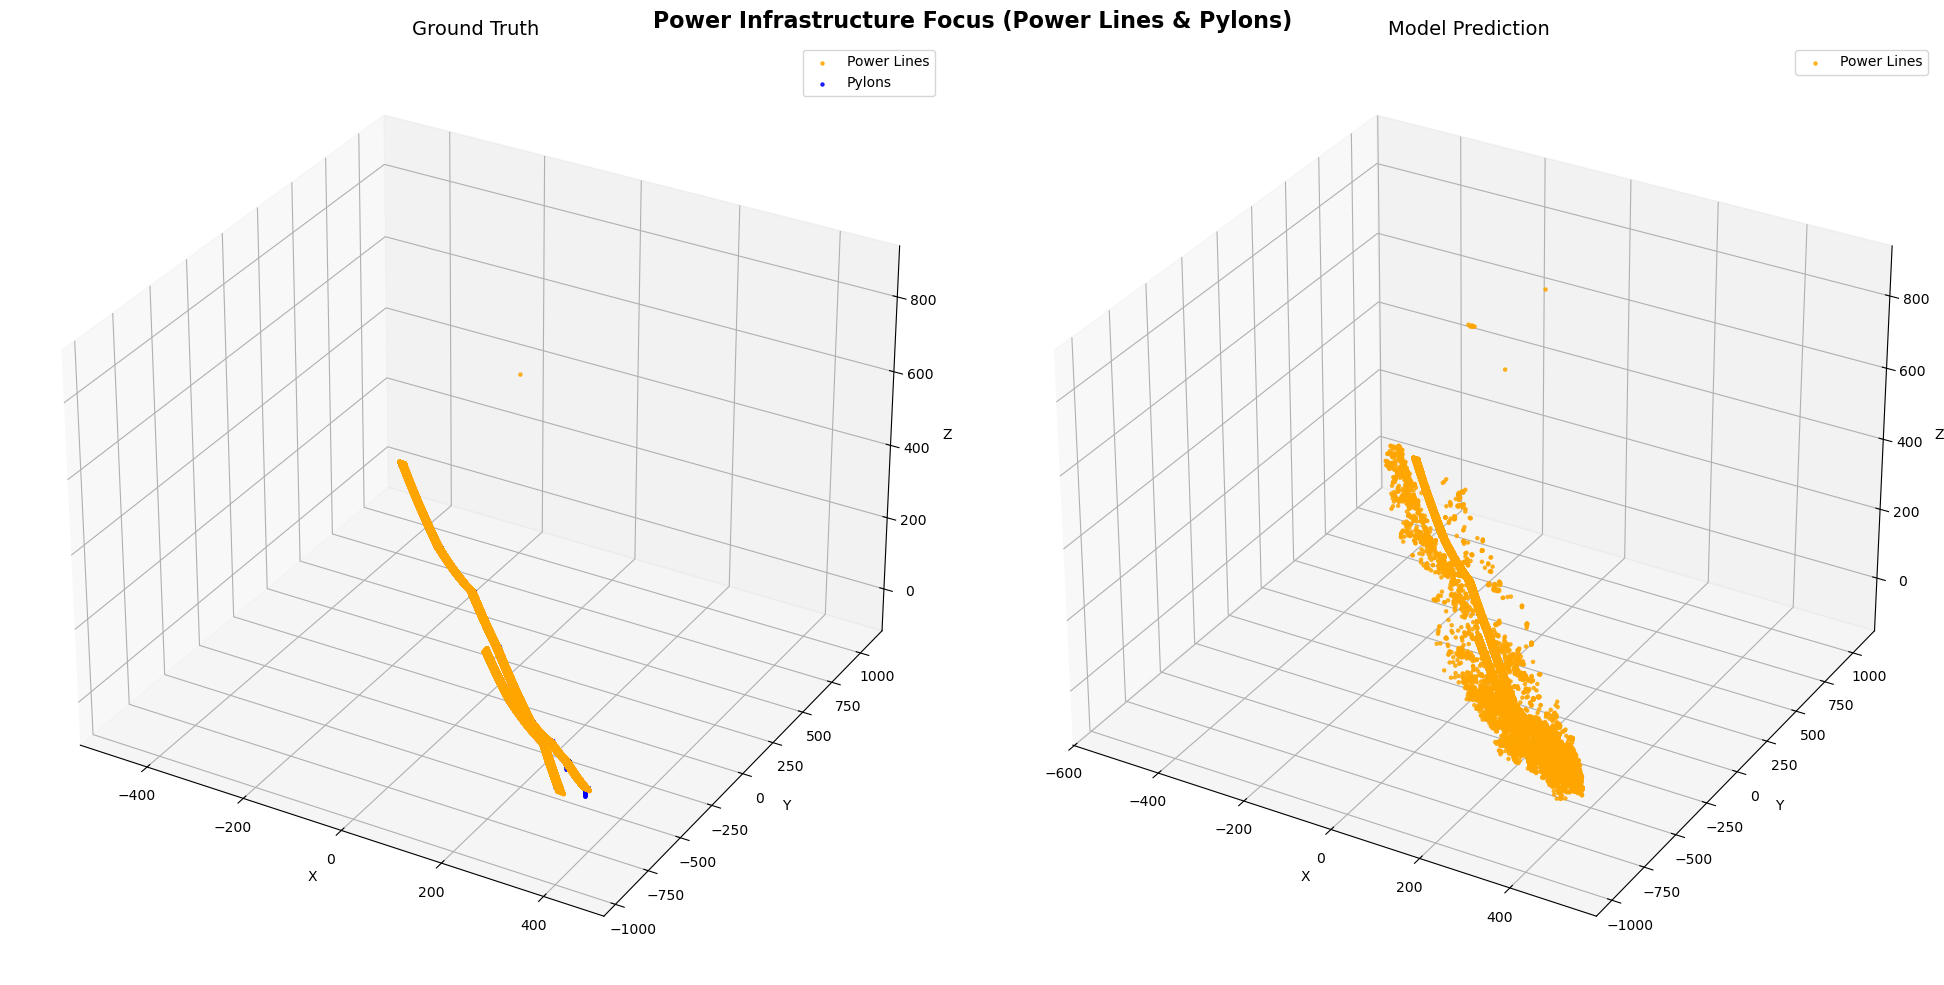

Saved power lines focus to full_reconstructions/powerlines_focus.png


In [ ]:
# Focus on power infrastructure
fig = plt.figure(figsize=FIGURE_SIZE)
fig.suptitle('Power Infrastructure Focus (Power Lines & Pylons)', fontsize=16, fontweight='bold')

# Ground Truth
ax1 = fig.add_subplot(121, projection='3d')
ax1.set_title('Ground Truth', fontsize=14)

# Show only power lines and pylons
powerline_mask_gt = all_labels == 1
pylon_mask_gt = all_labels == 2

if powerline_mask_gt.sum() > 0:
    ax1.scatter(all_points[powerline_mask_gt, 0], all_points[powerline_mask_gt, 1], 
               all_points[powerline_mask_gt, 2], c='orange', label='Power Lines', s=5, alpha=0.8)
if pylon_mask_gt.sum() > 0:
    ax1.scatter(all_points[pylon_mask_gt, 0], all_points[pylon_mask_gt, 1], 
               all_points[pylon_mask_gt, 2], c='blue', label='Pylons', s=5, alpha=0.8)

ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.legend(loc='upper right')

# Prediction
ax2 = fig.add_subplot(122, projection='3d')
ax2.set_title('Model Prediction', fontsize=14)

powerline_mask_pred = all_predictions == 1
pylon_mask_pred = all_predictions == 2

if powerline_mask_pred.sum() > 0:
    ax2.scatter(all_points[powerline_mask_pred, 0], all_points[powerline_mask_pred, 1], 
               all_points[powerline_mask_pred, 2], c='orange', label='Power Lines', s=5, alpha=0.8)
if pylon_mask_pred.sum() > 0:
    ax2.scatter(all_points[pylon_mask_pred, 0], all_points[pylon_mask_pred, 1], 
               all_points[pylon_mask_pred, 2], c='blue', label='Pylons', s=5, alpha=0.8)

ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/powerlines_focus.png', dpi=DPI, bbox_inches='tight')
plt.show()

print(f"Saved power lines focus to {OUTPUT_DIR}/powerlines_focus.png")

## 10. Save Reconstructed Point Cloud

In [ ]:
# Save as numpy array
output_data = {
    'points': all_points,
    'labels': all_labels,
    'predictions': all_predictions,
    'class_names': CLASS_NAMES,
    'metrics': metrics
}

np.save(f'{OUTPUT_DIR}/full_pointcloud.npy', output_data)
print(f"\nSaved full point cloud data to {OUTPUT_DIR}/full_pointcloud.npy")

# Save metrics as text
with open(f'{OUTPUT_DIR}/full_metrics.txt', 'w') as f:
    f.write("="*80 + "\n")
    f.write("FULL POINT CLOUD RECONSTRUCTION METRICS\n")
    f.write("="*80 + "\n\n")
    f.write(f"Total points: {len(all_points):,}\n")
    f.write(f"Number of chunks: {len(chunk_files)}\n")
    f.write(f"Checkpoint: {CHECKPOINT_PATH}\n\n")
    
    for class_name, class_metrics in metrics.items():
        f.write(f"{class_name}:\n")
        f.write(f"  IoU:       {class_metrics['IoU']:.4f}\n")
        f.write(f"  Precision: {class_metrics['Precision']:.4f}\n")
        f.write(f"  Recall:    {class_metrics['Recall']:.4f}\n")
        f.write(f"  F1-Score:  {class_metrics['F1']:.4f}\n")
        f.write(f"  Points:    {class_metrics['Count']:,}\n\n")
    
    f.write(f"Mean IoU: {mean_iou:.4f}\n")
    f.write(f"Overall Accuracy: {(all_predictions == all_labels).mean():.4f}\n")

print(f"Saved metrics to {OUTPUT_DIR}/full_metrics.txt")

print(f"\n{'='*80}")
print("RECONSTRUCTION COMPLETE!")
print(f"{'='*80}")
print(f"All outputs saved to: {OUTPUT_DIR}/")
print(f"  - full_pointcloud_topview.png")
print(f"  - full_pointcloud_3d.png")
print(f"  - powerlines_focus.png")
print(f"  - full_pointcloud.npy")
print(f"  - full_metrics.txt")


Saved full point cloud data to full_reconstructions/full_pointcloud.npy
Saved metrics to full_reconstructions/full_metrics.txt

RECONSTRUCTION COMPLETE!
All outputs saved to: full_reconstructions/
  - full_pointcloud_topview.png
  - full_pointcloud_3d.png
  - powerlines_focus.png
  - full_pointcloud.npy
  - full_metrics.txt


## Summary

This notebook:
1. ✅ Loaded all test set chunks
2. ✅ Ran predictions on each chunk
3. ✅ Denormalized points back to original coordinates
4. ✅ Assembled full point cloud from all chunks
5. ✅ Computed metrics on the complete reconstruction
6. ✅ Visualized ground truth vs predictions
7. ✅ Generated focused views of power infrastructure
8. ✅ Saved all results for further analysis

**Key Insights:**
- The spatial grid chunking preserves the original layout
- You can see the full extent of the test area
- Power lines and pylons can be visualized in their original context
- Metrics are computed on the complete reconstruction (not averaged per chunk)

In [ ]:
# Export as LAS files
try:
    import laspy
    
    print("Exporting point clouds as LAS files...")
    
    # Label mapping for LAS (inverse of preprocessing)
    # Model classes (0-indexed): 0=Vegetation, 1=PowerLines, 2=Pylons, 3=Others
    # LAS classes: 5=Vegetation, 10=PowerLines, 11=Pylons, 0=Others
    label_mapping_gt = {0: 5, 1: 10, 2: 11, 3: 0}
    label_mapping_pred = {0: 5, 1: 10, 2: 11, 3: 0}
    
    # Map labels back to LAS classification codes
    las_labels_gt = np.array([label_mapping_gt[label] for label in all_labels])
    las_labels_pred = np.array([label_mapping_pred[label] for label in all_predictions])
    
    # Create LAS file header
    header = laspy.LasHeader(version="1.2", point_format=3)
    header.offsets = [all_points[:, 0].min(), all_points[:, 1].min(), all_points[:, 2].min()]
    header.scales = [0.001, 0.001, 0.001]  # 1mm precision
    
    # Create LAS with ground truth labels
    print(f"\\n1. Creating LAS file with ground truth labels...")
    las_gt = laspy.LasData(header)
    las_gt.x = all_points[:, 0]
    las_gt.y = all_points[:, 1]
    las_gt.z = all_points[:, 2]
    las_gt.classification = las_labels_gt.astype(np.uint8)
    
    # Add RGB colors based on class
    rgb_colors_gt = np.zeros((len(all_points), 3), dtype=np.uint16)
    for cls in range(4):
        mask = all_labels == cls
        if cls == 0:  # Vegetation - dark green
            rgb_colors_gt[mask] = [0, 25600, 0]
        elif cls == 1:  # Power Lines - orange
            rgb_colors_gt[mask] = [65535, 35840, 0]
        elif cls == 2:  # Pylons - blue
            rgb_colors_gt[mask] = [0, 0, 65535]
        else:  # Others - gray
            rgb_colors_gt[mask] = [32768, 32768, 32768]
    
    las_gt.red = rgb_colors_gt[:, 0]
    las_gt.green = rgb_colors_gt[:, 1]
    las_gt.blue = rgb_colors_gt[:, 2]
    
    gt_path = f'{OUTPUT_DIR}/full_pointcloud_groundtruth.las'
    las_gt.write(gt_path)
    print(f"   Saved: {gt_path}")
    print(f"   Points: {len(all_points):,}")
    print(f"   Classes: {np.unique(las_labels_gt)}")
    
    # Create LAS with predictions
    print(f"\\n2. Creating LAS file with model predictions...")
    las_pred = laspy.LasData(header)
    las_pred.x = all_points[:, 0]
    las_pred.y = all_points[:, 1]
    las_pred.z = all_points[:, 2]
    las_pred.classification = las_labels_pred.astype(np.uint8)
    
    # Add RGB colors based on predicted class
    rgb_colors_pred = np.zeros((len(all_points), 3), dtype=np.uint16)
    for cls in range(4):
        mask = all_predictions == cls
        if cls == 0:  # Vegetation - dark green
            rgb_colors_pred[mask] = [0, 25600, 0]
        elif cls == 1:  # Power Lines - orange
            rgb_colors_pred[mask] = [65535, 35840, 0]
        elif cls == 2:  # Pylons - blue
            rgb_colors_pred[mask] = [0, 0, 65535]
        else:  # Others - gray
            rgb_colors_pred[mask] = [32768, 32768, 32768]
    
    las_pred.red = rgb_colors_pred[:, 0]
    las_pred.green = rgb_colors_pred[:, 1]
    las_pred.blue = rgb_colors_pred[:, 2]
    
    pred_path = f'{OUTPUT_DIR}/full_pointcloud_predictions.las'
    las_pred.write(pred_path)
    print(f"   Saved: {pred_path}")
    print(f"   Points: {len(all_points):,}")
    print(f"   Classes: {np.unique(las_labels_pred)}")
    
    # Create LAS with comparison (ground truth classification, prediction as intensity)
    print(f"\\n3. Creating LAS file with comparison (GT classification + prediction intensity)...")
    las_compare = laspy.LasData(header)
    las_compare.x = all_points[:, 0]
    las_compare.y = all_points[:, 1]
    las_compare.z = all_points[:, 2]
    las_compare.classification = las_labels_gt.astype(np.uint8)
    las_compare.intensity = las_labels_pred.astype(np.uint16)  # Store prediction in intensity field
    
    # Color by correctness: green=correct, red=incorrect
    correct_mask = all_labels == all_predictions
    rgb_colors_compare = np.zeros((len(all_points), 3), dtype=np.uint16)
    rgb_colors_compare[correct_mask] = [0, 65535, 0]  # Green for correct
    rgb_colors_compare[~correct_mask] = [65535, 0, 0]  # Red for incorrect
    
    las_compare.red = rgb_colors_compare[:, 0]
    las_compare.green = rgb_colors_compare[:, 1]
    las_compare.blue = rgb_colors_compare[:, 2]
    
    compare_path = f'{OUTPUT_DIR}/full_pointcloud_comparison.las'
    las_compare.write(compare_path)
    print(f"   Saved: {compare_path}")
    print(f"   Classification field: Ground truth")
    print(f"   Intensity field: Predictions")
    print(f"   RGB color: Green=Correct, Red=Incorrect")
    print(f"   Accuracy: {correct_mask.mean()*100:.2f}%")
    
    print(f"\\n{'='*80}")
    print("LAS EXPORT COMPLETE!")
    print(f"{'='*80}")
    print(f"\\nLAS files saved to: {OUTPUT_DIR}/")
    print(f"  1. full_pointcloud_groundtruth.las")
    print(f"  2. full_pointcloud_predictions.las")
    print(f"  3. full_pointcloud_comparison.las")
    print(f"\\nYou can now open these files in CloudCompare, QGIS, or any LAS viewer!")
    print(f"\\nClass codes in LAS files:")
    print(f"  5  = High Vegetation (Dark Green)")
    print(f"  10 = Power Lines (Orange)")
    print(f"  11 = Pylons (Blue)")
    print(f"  0  = Others (Gray)")
    
except ImportError:
    print("ERROR: laspy not installed!")
    print("Install with: pip install laspy")
    print("Then re-run this cell to export LAS files.")

Exporting point clouds as LAS files...
\n1. Creating LAS file with ground truth labels...
   Saved: full_reconstructions/full_pointcloud_groundtruth.las
   Points: 22,490,678
   Classes: [ 0  5 10 11]
\n2. Creating LAS file with model predictions...
   Saved: full_reconstructions/full_pointcloud_predictions.las
   Points: 22,490,678
   Classes: [ 0  5 10]
\n3. Creating LAS file with comparison (GT classification + prediction intensity)...
   Saved: full_reconstructions/full_pointcloud_comparison.las
   Classification field: Ground truth
   Intensity field: Predictions
   RGB color: Green=Correct, Red=Incorrect
   Accuracy: 71.84%
\n================================================================================
LAS EXPORT COMPLETE!
\nLAS files saved to: full_reconstructions/
  1. full_pointcloud_groundtruth.las
  2. full_pointcloud_predictions.las
  3. full_pointcloud_comparison.las
\nYou can now open these files in CloudCompare, QGIS, or any LAS viewer!
\nClass codes in LAS files:
  5

## 11. Export as LAS Files